# Assignment: Classification Model Comparison

## Step 1: Dataset Choice

### Dataset Name

Heart Disease Prediction Dataset

### Source

heart.csv

### Problem Type

Binary Classification

### Problem Statement

The objective is to predict whether a patient has heart disease using
13 clinical and demographic attributes.

Target Variable:

target

- 0 = No Heart Disease
- 1 = Heart Disease

### Why This Dataset?

This dataset was selected because:

1. It satisfies the assignment requirement of having more than 500 records.
2. It contains more than 12 features.
3. It represents a real-world healthcare prediction problem.
4. It supports binary classification.
5. It is suitable for comparing multiple machine learning classifiers.

In [174]:
# ==========================================================
# IMPORT REQUIRED LIBRARIES
# ==========================================================

import pandas as pd
import numpy as np

# ==========================================================
# LOAD DATASET
# ==========================================================

df = pd.read_csv("heart.csv")

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [175]:
# ==========================================================
# DATASET SHAPE
# ==========================================================

print("Dataset Shape\n")

print(df.shape)

print("\nNumber of Records")

print(df.shape[0])

print("\nNumber of Columns")

print(df.shape[1])

Dataset Shape

(1025, 14)

Number of Records
1025

Number of Columns
14


In [176]:
# ==========================================================
# COLUMN NAMES
# ==========================================================

print("Column Names\n")

for column in df.columns:

    print(column)

Column Names

age
sex
cp
trestbps
chol
fbs
restecg
thalach
exang
oldpeak
slope
ca
thal
target


In [177]:
# ==========================================================
# FIRST FIVE ROWS
# ==========================================================

print(df.head())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [178]:
# ==========================================================
# DATA TYPES
# ==========================================================

print(df.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


In [179]:
# ==========================================================
# CHECK MISSING VALUES
# ==========================================================

print("Missing Values Per Column\n")

print(df.isnull().sum())

print(
    "\nTotal Missing Values:",
    df.isnull().sum().sum()
)


Missing Values Per Column

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total Missing Values: 0


In [180]:
# ==========================================================
# DATASET SUMMARY
# ==========================================================

summary = pd.DataFrame({

    "Property":[
        "Records",
        "Input Features",
        "Target Classes",
        "Missing Values"
    ],

    "Value":[
        len(df),
        len(df.columns)-1,
        df["target"].nunique(),
        df.isnull().sum().sum()
    ]

})

print(summary)

         Property  Value
0         Records   1025
1  Input Features     13
2  Target Classes      2
3  Missing Values      0


In [181]:
# ==========================================================
# TARGET DISTRIBUTION
# ==========================================================

print("Target Distribution\n")

print(
    df["target"]
    .value_counts()
)

Target Distribution

target
1    526
0    499
Name: count, dtype: int64


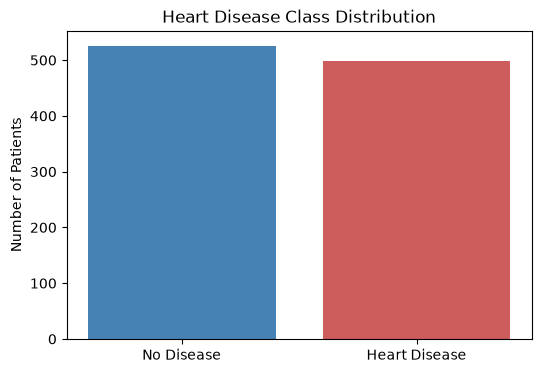

In [182]:
# ==========================================================
# TARGET CLASS DISTRIBUTION
# ==========================================================

import matplotlib.pyplot as plt

target_counts = (
    df["target"]
    .value_counts()
)

plt.figure(figsize=(6,4))

plt.bar(

    ["No Disease", "Heart Disease"],

    target_counts.values,

    color=[
        "steelblue",
        "indianred"
    ]

)

plt.title(
    "Heart Disease Class Distribution"
)

plt.ylabel(
    "Number of Patients"
)

plt.show()

# Step 1 Observations

1. The dataset contains 1025 patient records.

2. The dataset contains 13 predictor variables and 1 target variable.

3. No missing values are present.

4. The target variable is binary:

   - 0 = No Heart Disease
   - 1 = Heart Disease

5. The classes are reasonably balanced, making the dataset suitable for classification tasks.

6. The dataset satisfies all assignment requirements regarding the number of samples and features.

# Step 2: Data Preprocessing

## Objective

Prepare the dataset for machine learning by:

1. Separating features and target variable.
2. Checking feature types.
3. Splitting the dataset into training and testing sets.
4. Standardizing numerical variables.
5. Creating a reusable test dataset for later model evaluation.

The same preprocessing pipeline will be used for all five classification models.

In [183]:
# ==========================================================
# SEPARATE INPUT FEATURES AND TARGET
# ==========================================================

X = df.drop(
    "target",
    axis=1
)

y = df["target"]

print("Feature Matrix Shape")
print(X.shape)

print("\nTarget Vector Shape")
print(y.shape)

Feature Matrix Shape
(1025, 13)

Target Vector Shape
(1025,)


In [184]:
# ==========================================================
# FEATURE DATA TYPES
# ==========================================================

print("Feature Data Types\n")

print(X.dtypes)

Feature Data Types

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
dtype: object


In [185]:
# ==========================================================
# FEATURE SUMMARY
# ==========================================================

summary_df = pd.DataFrame({

    "Feature": X.columns,

    "Minimum": X.min(),

    "Maximum": X.max(),

    "Mean": X.mean().round(2)

})

print(summary_df)

           Feature  Minimum  Maximum    Mean
age            age     29.0     77.0   54.43
sex            sex      0.0      1.0    0.70
cp              cp      0.0      3.0    0.94
trestbps  trestbps     94.0    200.0  131.61
chol          chol    126.0    564.0  246.00
fbs            fbs      0.0      1.0    0.15
restecg    restecg      0.0      2.0    0.53
thalach    thalach     71.0    202.0  149.11
exang        exang      0.0      1.0    0.34
oldpeak    oldpeak      0.0      6.2    1.07
slope        slope      0.0      2.0    1.39
ca              ca      0.0      4.0    0.75
thal          thal      0.0      3.0    2.32


In [186]:
# ==========================================================
# TRAIN TEST SPLIT
# ==========================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

print("Training Features")
print(X_train.shape)

print("\nTesting Features")
print(X_test.shape)

print("\nTraining Labels")
print(y_train.shape)

print("\nTesting Labels")
print(y_test.shape)

Training Features
(820, 13)

Testing Features
(205, 13)

Training Labels
(820,)

Testing Labels
(205,)


In [187]:
stratify=y

1. Heart Disease

2. No Heart Disease

In [188]:
# ==========================================================
# CLASS DISTRIBUTION
# ==========================================================

print("Training Target Distribution\n")

print(
    y_train.value_counts()
)

print("\nTesting Target Distribution\n")

print(
    y_test.value_counts()
)

Training Target Distribution

target
1    421
0    399
Name: count, dtype: int64

Testing Target Distribution

target
1    105
0    100
Name: count, dtype: int64


In [189]:
# ==========================================================
# FEATURE SCALING
# ==========================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print(
    "Training Data Scaled"
)

print(
    X_train_scaled.shape
)

Training Data Scaled
(820, 13)


In [190]:
# ==========================================================
# VERIFY SCALING
# ==========================================================

scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)

print("Means\n")

print(
    scaled_df.mean().round(2)
)

print("\nStandard Deviations\n")

print(
    scaled_df.std().round(2)
)

Means

age        -0.0
sex         0.0
cp          0.0
trestbps    0.0
chol       -0.0
fbs        -0.0
restecg    -0.0
thalach     0.0
exang      -0.0
oldpeak     0.0
slope      -0.0
ca          0.0
thal       -0.0
dtype: float64

Standard Deviations

age         1.0
sex         1.0
cp          1.0
trestbps    1.0
chol        1.0
fbs         1.0
restecg     1.0
thalach     1.0
exang       1.0
oldpeak     1.0
slope       1.0
ca          1.0
thal        1.0
dtype: float64


test_data.csv

In [191]:
# ==========================================================
# CREATE TEST_DATA.CSV
# ==========================================================

test_data = X_test.copy()

test_data["target"] = y_test

test_data.to_csv(
    "test_data.csv",
    index=False
)

print(
    "test_data.csv created successfully"
)

test_data.csv created successfully


In [192]:
# ==========================================================
# SAVE SCALER
# ==========================================================

import joblib
import os

os.makedirs(
    "models",
    exist_ok=True
)

joblib.dump(
    scaler,
    "models/scaler.pkl"
)

print(
    "Scaler saved successfully"
)

Scaler saved successfully


# Step 2 Observations

1. Input features and target variable were successfully separated.

2. All features in the Heart Disease dataset are already numerical.

3. No categorical encoding was necessary.

4. The dataset was split into:

   - 80% training data
   - 20% testing data

5. Feature scaling was applied using StandardScaler.

6. The same scaler was saved for later use in the Streamlit application.

7. A test_data.csv file was created as required by the assignment.

# Step 3: Logistic Regression Classifier

## Objective

Train a Logistic Regression model on the Heart Disease dataset and evaluate its classification performance.

---

## Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for binary classification.

It predicts the probability that a data point belongs to the positive class.

### Decision Function

A linear combination of input features is computed:

z = w₁x₁ + w₂x₂ + ... + wₙxₙ + b

The sigmoid function converts this value into a probability:

P(y=1)

If the probability is greater than 0.5, the sample is classified as:

Class 1 → Heart Disease

Otherwise:

Class 0 → No Heart Disease

---

## Evaluation Metrics

The following assignment metrics will be computed:

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)

In [193]:
# ==========================================================
# IMPORT MODEL AND METRICS
# ==========================================================

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

In [194]:
# ==========================================================
# TRAIN LOGISTIC REGRESSION
# ==========================================================

logistic_model = LogisticRegression(
    max_iter=5000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

print(
    "Logistic Regression Trained Successfully"
)

Logistic Regression Trained Successfully


In [195]:
# ==========================================================
# PREDICTIONS
# ==========================================================

logistic_predictions = (
    logistic_model.predict(
        X_test_scaled
    )
)

logistic_probabilities = (
    logistic_model.predict_proba(
        X_test_scaled
    )[:, 1]
)

print(
    "Predictions Generated"
)

Predictions Generated


In [196]:
# ==========================================================
# EVALUATION METRICS
# ==========================================================

lr_accuracy = accuracy_score(

    y_test,

    logistic_predictions

)

lr_auc = roc_auc_score(

    y_test,

    logistic_probabilities

)

lr_precision = precision_score(

    y_test,

    logistic_predictions

)

lr_recall = recall_score(

    y_test,

    logistic_predictions

)

lr_f1 = f1_score(

    y_test,

    logistic_predictions

)

lr_mcc = matthews_corrcoef(

    y_test,

    logistic_predictions

)

print("Logistic Regression Results\n")

print(
    "Accuracy:",
    round(lr_accuracy,4)
)

print(
    "AUC:",
    round(lr_auc,4)
)

print(
    "Precision:",
    round(lr_precision,4)
)

print(
    "Recall:",
    round(lr_recall,4)
)

print(
    "F1 Score:",
    round(lr_f1,4)
)

print(
    "MCC:",
    round(lr_mcc,4)
)

Logistic Regression Results

Accuracy: 0.8098
AUC: 0.9298
Precision: 0.7619
Recall: 0.9143
F1 Score: 0.8312
MCC: 0.6309


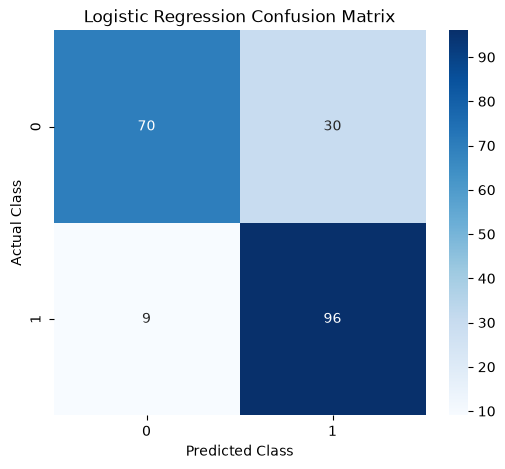

In [197]:
# ==========================================================
# CONFUSION MATRIX
# ==========================================================

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(

    y_test,

    logistic_predictions

)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues"

)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.show()

In [198]:
# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print(

    classification_report(

        y_test,

        logistic_predictions

    )

)

              precision    recall  f1-score   support

           0       0.89      0.70      0.78       100
           1       0.76      0.91      0.83       105

    accuracy                           0.81       205
   macro avg       0.82      0.81      0.81       205
weighted avg       0.82      0.81      0.81       205



In [199]:
# ==========================================================
# SAVE MODEL
# ==========================================================

import joblib

joblib.dump(

    logistic_model,

    "models/logistic_regression.pkl"

)

print(
    "Model Saved Successfully"
)

Model Saved Successfully


In [200]:
# ==========================================================
# STORE RESULTS
# ==========================================================

results = []

results.append({

    "Model":
    "Logistic Regression",

    "Accuracy":
    lr_accuracy,

    "AUC":
    lr_auc,

    "Precision":
    lr_precision,

    "Recall":
    lr_recall,

    "F1":
    lr_f1,

    "MCC":
    lr_mcc

})

# Step 3 Observations

1. Logistic Regression was successfully trained on the Heart Disease dataset.

2. The model provides probability-based predictions using the sigmoid function.

3. Evaluation metrics including Accuracy, AUC, Precision, Recall, F1 Score and MCC were computed.

4. The confusion matrix shows the model's classification performance on unseen test data.

5. Logistic Regression serves as the baseline model against which the remaining classifiers will be compared.

# Step 4: Decision Tree Classifier

## Objective

Train a Decision Tree classifier on the Heart Disease dataset and evaluate its performance using the required evaluation metrics.

---

## Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm that creates a sequence of decision rules to classify observations.

The model repeatedly splits the data according to the feature that provides the best separation between classes.

For example:

Age > 55 ?

↓

Cholesterol > 240 ?

↓

Heart Disease / No Heart Disease

---

## Advantages

1. Easy to interpret.
2. Can model nonlinear relationships.
3. Requires little data preparation.
4. Handles interactions between variables naturally.

---

## Evaluation Metrics

The assignment requires:

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)

In [201]:
# ==========================================================
# IMPORT DECISION TREE
# ==========================================================

from sklearn.tree import DecisionTreeClassifier

In [202]:
# ==========================================================
# TRAIN DECISION TREE
# ==========================================================

decision_tree_model = DecisionTreeClassifier(

    random_state=42,

    max_depth=5

)

decision_tree_model.fit(

    X_train_scaled,

    y_train

)

print(
    "Decision Tree Trained Successfully"
)

Decision Tree Trained Successfully


In [203]:
# ==========================================================
# PREDICTIONS
# ==========================================================

dt_predictions = (

    decision_tree_model.predict(
        X_test_scaled
    )

)

dt_probabilities = (

    decision_tree_model.predict_proba(
        X_test_scaled
    )[:,1]

)

print(
    "Predictions Generated"
)

Predictions Generated


In [204]:
# ==========================================================
# DECISION TREE METRICS
# ==========================================================

dt_accuracy = accuracy_score(

    y_test,

    dt_predictions

)

dt_auc = roc_auc_score(

    y_test,

    dt_probabilities

)

dt_precision = precision_score(

    y_test,

    dt_predictions

)

dt_recall = recall_score(

    y_test,

    dt_predictions

)

dt_f1 = f1_score(

    y_test,

    dt_predictions

)

dt_mcc = matthews_corrcoef(

    y_test,

    dt_predictions

)

print("Decision Tree Results\n")

print(
    "Accuracy:",
    round(dt_accuracy,4)
)

print(
    "AUC:",
    round(dt_auc,4)
)

print(
    "Precision:",
    round(dt_precision,4)
)

print(
    "Recall:",
    round(dt_recall,4)
)

print(
    "F1 Score:",
    round(dt_f1,4)
)

print(
    "MCC:",
    round(dt_mcc,4)
)

Decision Tree Results

Accuracy: 0.8732
AUC: 0.9326
Precision: 0.8624
Recall: 0.8952
F1 Score: 0.8785
MCC: 0.7465


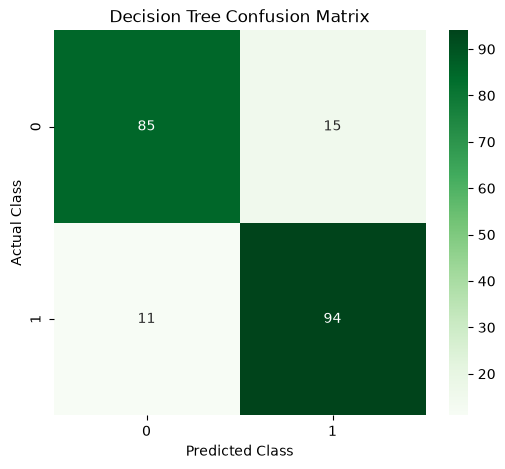

In [205]:
# ==========================================================
# CONFUSION MATRIX
# ==========================================================

cm_dt = confusion_matrix(

    y_test,

    dt_predictions

)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm_dt,

    annot=True,

    fmt="d",

    cmap="Greens"

)

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.show()

In [206]:
# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print(

    classification_report(

        y_test,

        dt_predictions

    )

)

              precision    recall  f1-score   support

           0       0.89      0.85      0.87       100
           1       0.86      0.90      0.88       105

    accuracy                           0.87       205
   macro avg       0.87      0.87      0.87       205
weighted avg       0.87      0.87      0.87       205



In [207]:
# ==========================================================
# FEATURE IMPORTANCE
# ==========================================================

feature_importance_df = pd.DataFrame({

    "Feature":
    X.columns,

    "Importance":
    decision_tree_model.feature_importances_

})

feature_importance_df = (

    feature_importance_df

    .sort_values(
        "Importance",
        ascending=False
    )

)

print(
    feature_importance_df
)

     Feature  Importance
2         cp    0.372280
11        ca    0.138164
0        age    0.109885
12      thal    0.088238
9    oldpeak    0.063845
4       chol    0.053462
1        sex    0.046021
7    thalach    0.040041
8      exang    0.034112
6    restecg    0.027317
3   trestbps    0.026634
5        fbs    0.000000
10     slope    0.000000


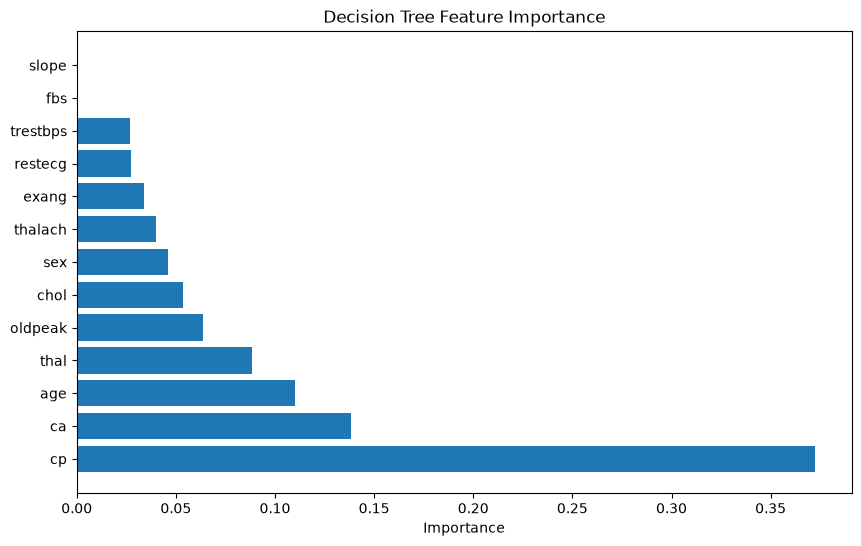

In [208]:
# ==========================================================
# FEATURE IMPORTANCE PLOT
# ==========================================================

plt.figure(figsize=(10,6))

plt.barh(

    feature_importance_df["Feature"],

    feature_importance_df["Importance"]

)

plt.title(
    "Decision Tree Feature Importance"
)

plt.xlabel(
    "Importance"
)

plt.show()

In [209]:
# ==========================================================
# SAVE MODEL
# ==========================================================

joblib.dump(

    decision_tree_model,

    "models/decision_tree.pkl"

)

print(
    "Decision Tree Saved Successfully"
)

Decision Tree Saved Successfully


In [210]:
# ==========================================================
# STORE RESULTS
# ==========================================================

results.append({

    "Model":
    "Decision Tree",

    "Accuracy":
    dt_accuracy,

    "AUC":
    dt_auc,

    "Precision":
    dt_precision,

    "Recall":
    dt_recall,

    "F1":
    dt_f1,

    "MCC":
    dt_mcc

})

# Step 4 Observations

1. The Decision Tree classifier was trained successfully.

2. The model generates decision rules to classify patients into:

   - Heart Disease
   - No Heart Disease

3. The feature importance values indicate which clinical variables contribute most strongly to the model's decisions.

4. Decision Trees can capture nonlinear relationships that may not be represented effectively by Logistic Regression.

5. The obtained metrics will later be compared against all remaining classifiers.

# Step 5: K-Nearest Neighbors (KNN) Classifier

## Objective

Train a K-Nearest Neighbors (KNN) classifier on the Heart Disease dataset and evaluate its performance.

---

## What is KNN?

KNN is an instance-based learning algorithm.

For a new patient:

1. Calculate the distance between the new patient and all training examples.
2. Identify the K closest neighbors.
3. Allow the neighbors to vote.
4. Assign the most common class.

---

## Example

Suppose:

K = 5

Among the 5 nearest neighbors:

- 4 have Heart Disease
- 1 does not have Heart Disease

Prediction:

Heart Disease

---

## Why Scaling Is Important

KNN relies on distance calculations.

If variables have different scales:

- Cholesterol may dominate Age.
- Blood Pressure may dominate other variables.

Therefore feature scaling is essential before applying KNN.

---

## Evaluation Metrics

The assignment requires:

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)

In [211]:
# ==========================================================
# IMPORT KNN CLASSIFIER
# ==========================================================

from sklearn.neighbors import KNeighborsClassifier

In [212]:
# ==========================================================
# TRAIN KNN MODEL
# ==========================================================

knn_model = KNeighborsClassifier(

    n_neighbors=5

)

knn_model.fit(

    X_train_scaled,

    y_train

)

print(
    "KNN Model Trained Successfully"
)

KNN Model Trained Successfully


In [213]:
# ==========================================================
# KNN PREDICTIONS
# ==========================================================

knn_predictions = (

    knn_model.predict(
        X_test_scaled
    )

)

knn_probabilities = (

    knn_model.predict_proba(
        X_test_scaled
    )[:,1]

)

print(
    "Predictions Generated"
)

Predictions Generated


In [214]:
# ==========================================================
# KNN METRICS
# ==========================================================

knn_accuracy = accuracy_score(

    y_test,

    knn_predictions

)

knn_auc = roc_auc_score(

    y_test,

    knn_probabilities

)

knn_precision = precision_score(

    y_test,

    knn_predictions

)

knn_recall = recall_score(

    y_test,

    knn_predictions

)

knn_f1 = f1_score(

    y_test,

    knn_predictions

)

knn_mcc = matthews_corrcoef(

    y_test,

    knn_predictions

)

print("KNN Results\n")

print(
    "Accuracy:",
    round(knn_accuracy,4)
)

print(
    "AUC:",
    round(knn_auc,4)
)

print(
    "Precision:",
    round(knn_precision,4)
)

print(
    "Recall:",
    round(knn_recall,4)
)

print(
    "F1 Score:",
    round(knn_f1,4)
)

print(
    "MCC:",
    round(knn_mcc,4)
)

KNN Results

Accuracy: 0.8634
AUC: 0.9629
Precision: 0.8738
Recall: 0.8571
F1 Score: 0.8654
MCC: 0.7269


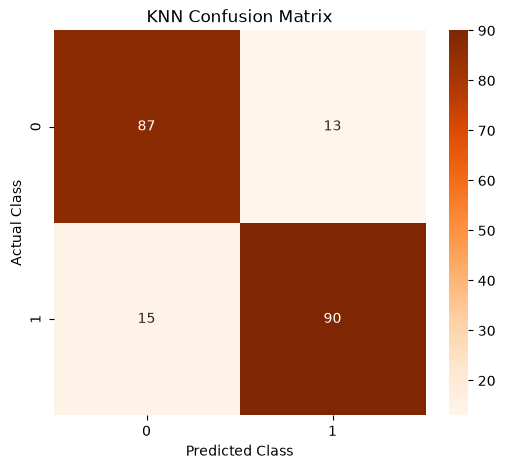

In [215]:
# ==========================================================
# KNN CONFUSION MATRIX
# ==========================================================

cm_knn = confusion_matrix(

    y_test,

    knn_predictions

)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm_knn,

    annot=True,

    fmt="d",

    cmap="Oranges"

)

plt.title(
    "KNN Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.show()


In [216]:
# ==========================================================
# KNN CLASSIFICATION REPORT
# ==========================================================

print(

    classification_report(

        y_test,

        knn_predictions

    )

)

              precision    recall  f1-score   support

           0       0.85      0.87      0.86       100
           1       0.87      0.86      0.87       105

    accuracy                           0.86       205
   macro avg       0.86      0.86      0.86       205
weighted avg       0.86      0.86      0.86       205



In [217]:
# ==========================================================
# K VALUE INFORMATION
# ==========================================================

print(
    "Number of Neighbors Used:"
)

print(
    knn_model.n_neighbors
)

Number of Neighbors Used:
5


In [218]:
# ==========================================================
# SAVE KNN MODEL
# ==========================================================

joblib.dump(

    knn_model,

    "models/knn.pkl"

)

print(
    "KNN Model Saved Successfully"
)

KNN Model Saved Successfully


In [219]:
# ==========================================================
# STORE RESULTS
# ==========================================================

results.append({

    "Model":
    "KNN",

    "Accuracy":
    knn_accuracy,

    "AUC":
    knn_auc,

    "Precision":
    knn_precision,

    "Recall":
    knn_recall,

    "F1":
    knn_f1,

    "MCC":
    knn_mcc

})

# Step 5 Observations

1. KNN classifies patients based on the behavior of nearby patients in the training data.

2. Unlike Logistic Regression and Decision Trees, KNN does not explicitly learn model coefficients or decision rules.

3. The model relies entirely on distance calculations.

4. Feature scaling is therefore essential for KNN performance.

5. The evaluation metrics obtained in this step will later be compared against the remaining classifiers.

6. The chosen value of K = 5 provides a balance between sensitivity to noise and predictive accuracy.

# Step 6: Gaussian Naive Bayes Classifier

## Objective

Train a Gaussian Naive Bayes classifier on the Heart Disease dataset and evaluate its performance using the required classification metrics.

---

## What is Naive Bayes?

Naive Bayes is a probabilistic classification algorithm based on Bayes' Theorem.

The model estimates:

P(Class | Features)

using:

P(Features | Class)

and the class prior probabilities.

---

## Why is it called "Naive"?

The algorithm assumes that all input features are conditionally independent given the class label.

For example, it assumes:

- Cholesterol is independent of Age
- Blood Pressure is independent of Chest Pain Type

In reality these assumptions are often false, but the algorithm still performs surprisingly well in many practical classification problems.

---

## Why Gaussian Naive Bayes?

Gaussian Naive Bayes is designed for continuous numerical variables.

It assumes that the values of each feature follow a normal (Gaussian) distribution within each class.

---

## Evaluation Metrics

The assignment requires:

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)

In [220]:
# ==========================================================
# IMPORT GAUSSIAN NAIVE BAYES
# ==========================================================

from sklearn.naive_bayes import GaussianNB

In [221]:
# ==========================================================
# TRAIN GAUSSIAN NAIVE BAYES
# ==========================================================

naive_bayes_model = GaussianNB()

naive_bayes_model.fit(

    X_train_scaled,

    y_train

)

print(
    "Gaussian Naive Bayes Trained Successfully"
)

Gaussian Naive Bayes Trained Successfully


In [222]:
# ==========================================================
# GENERATE PREDICTIONS
# ==========================================================

nb_predictions = (

    naive_bayes_model.predict(
        X_test_scaled
    )

)

nb_probabilities = (

    naive_bayes_model.predict_proba(
        X_test_scaled
    )[:,1]

)

print(
    "Predictions Generated"
)

Predictions Generated


In [223]:
# ==========================================================
# GAUSSIAN NAIVE BAYES METRICS
# ==========================================================

nb_accuracy = accuracy_score(

    y_test,

    nb_predictions

)

nb_auc = roc_auc_score(

    y_test,

    nb_probabilities

)

nb_precision = precision_score(

    y_test,

    nb_predictions

)

nb_recall = recall_score(

    y_test,

    nb_predictions

)

nb_f1 = f1_score(

    y_test,

    nb_predictions

)

nb_mcc = matthews_corrcoef(

    y_test,

    nb_predictions

)

print("Gaussian Naive Bayes Results\n")

print(
    "Accuracy:",
    round(nb_accuracy,4)
)

print(
    "AUC:",
    round(nb_auc,4)
)

print(
    "Precision:",
    round(nb_precision,4)
)

print(
    "Recall:",
    round(nb_recall,4)
)

print(
    "F1 Score:",
    round(nb_f1,4)
)

print(
    "MCC:",
    round(nb_mcc,4)
)

Gaussian Naive Bayes Results

Accuracy: 0.8293
AUC: 0.9043
Precision: 0.807
Recall: 0.8762
F1 Score: 0.8402
MCC: 0.6602


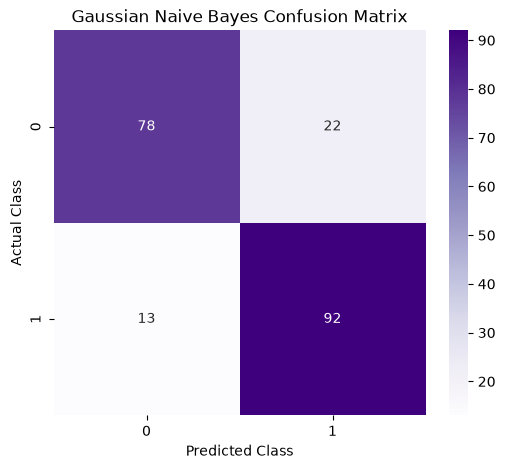

In [224]:
# ==========================================================
# CONFUSION MATRIX
# ==========================================================

cm_nb = confusion_matrix(

    y_test,

    nb_predictions

)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm_nb,

    annot=True,

    fmt="d",

    cmap="Purples"

)

plt.title(
    "Gaussian Naive Bayes Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.show()

In [225]:
# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print(

    classification_report(

        y_test,

        nb_predictions

    )

)

              precision    recall  f1-score   support

           0       0.86      0.78      0.82       100
           1       0.81      0.88      0.84       105

    accuracy                           0.83       205
   macro avg       0.83      0.83      0.83       205
weighted avg       0.83      0.83      0.83       205



In [226]:
# ==========================================================
# CLASS PRIOR PROBABILITIES
# ==========================================================

print(
    "Class Prior Probabilities\n"
)

print(
    naive_bayes_model.class_prior_
)

Class Prior Probabilities

[0.48658537 0.51341463]


In [227]:
# ==========================================================
# SAVE MODEL
# ==========================================================

joblib.dump(

    naive_bayes_model,

    "models/naive_bayes.pkl"

)

print(
    "Gaussian Naive Bayes Model Saved Successfully"
)

Gaussian Naive Bayes Model Saved Successfully


In [228]:
# ==========================================================
# STORE RESULTS
# ==========================================================

results.append({

    "Model":
    "Naive Bayes",

    "Accuracy":
    nb_accuracy,

    "AUC":
    nb_auc,

    "Precision":
    nb_precision,

    "Recall":
    nb_recall,

    "F1":
    nb_f1,

    "MCC":
    nb_mcc

})

# Step 6 Observations

1. Gaussian Naive Bayes was trained successfully.

2. The model uses Bayes' theorem together with class-conditional Gaussian distributions.

3. The algorithm assumes conditional independence among input features.

4. Despite its simplifying assumptions, Naive Bayes often performs competitively on classification tasks.

5. The evaluation metrics obtained in this step will later be compared with the remaining classifiers.

6. The class prior probabilities reflect the distribution of Heart Disease and No Heart Disease cases in the training dataset.

# Step 7: Support Vector Machine (SVM)

## Objective

Train a Support Vector Machine (SVM) classifier on the Heart Disease dataset and evaluate its classification performance.

---

## What is a Support Vector Machine?

A Support Vector Machine (SVM) is a supervised learning algorithm that finds the decision boundary which maximizes the separation between classes.

Unlike Logistic Regression, which fits a probabilistic linear boundary, an SVM attempts to maximize the margin between the nearest observations of different classes.

---

## Key Idea

Suppose two classes can be separated by many lines.

SVM chooses the boundary that leaves the largest possible gap between classes.

This often improves generalization on unseen data.

---

## Support Vectors

The observations closest to the decision boundary are called support vectors.

These points determine the position of the separating hyperplane.

---

## Why Feature Scaling Is Important

SVM relies heavily on distance calculations.

Therefore standardized features are essential.

This is why X_train_scaled and X_test_scaled are used.

---

## Evaluation Metrics

The assignment requires:

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)

In [229]:
# ==========================================================
# IMPORT SUPPORT VECTOR MACHINE
# ==========================================================

from sklearn.svm import SVC

In [230]:
# ==========================================================
# TRAIN SUPPORT VECTOR MACHINE
# ==========================================================

svm_model = SVC(

    kernel="rbf",

    probability=True,

    random_state=42

)

svm_model.fit(

    X_train_scaled,

    y_train

)

print(
    "Support Vector Machine Trained Successfully"
)

Support Vector Machine Trained Successfully


/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [231]:
# ==========================================================
# GENERATE PREDICTIONS
# ==========================================================

svm_predictions = (

    svm_model.predict(
        X_test_scaled
    )

)

svm_probabilities = (

    svm_model.predict_proba(
        X_test_scaled
    )[:,1]

)

print(
    "Predictions Generated"
)

Predictions Generated


In [232]:
# ==========================================================
# SVM METRICS
# ==========================================================

svm_accuracy = accuracy_score(

    y_test,

    svm_predictions

)

svm_auc = roc_auc_score(

    y_test,

    svm_probabilities

)

svm_precision = precision_score(

    y_test,

    svm_predictions

)

svm_recall = recall_score(

    y_test,

    svm_predictions

)

svm_f1 = f1_score(

    y_test,

    svm_predictions

)

svm_mcc = matthews_corrcoef(

    y_test,

    svm_predictions

)

print("Support Vector Machine Results\n")

print(
    "Accuracy:",
    round(svm_accuracy,4)
)

print(
    "AUC:",
    round(svm_auc,4)
)

print(
    "Precision:",
    round(svm_precision,4)
)

print(
    "Recall:",
    round(svm_recall,4)
)

print(
    "F1 Score:",
    round(svm_f1,4)
)

print(
    "MCC:",
    round(svm_mcc,4)
)

Support Vector Machine Results

Accuracy: 0.9268
AUC: 0.9771
Precision: 0.9167
Recall: 0.9429
F1 Score: 0.9296
MCC: 0.8538


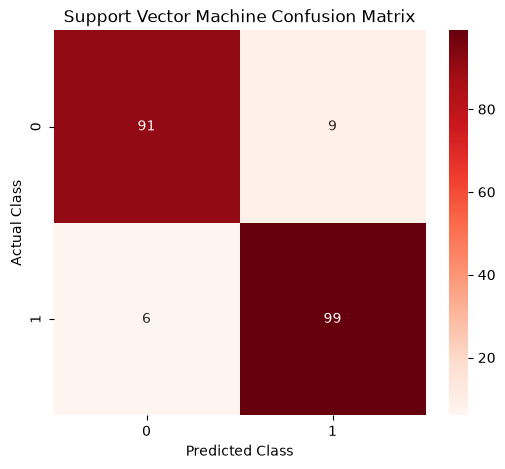

In [233]:
# ==========================================================
# CONFUSION MATRIX
# ==========================================================

cm_svm = confusion_matrix(

    y_test,

    svm_predictions

)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm_svm,

    annot=True,

    fmt="d",

    cmap="Reds"

)

plt.title(
    "Support Vector Machine Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.show()

In [234]:
# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print(

    classification_report(

        y_test,

        svm_predictions

    )

)

              precision    recall  f1-score   support

           0       0.94      0.91      0.92       100
           1       0.92      0.94      0.93       105

    accuracy                           0.93       205
   macro avg       0.93      0.93      0.93       205
weighted avg       0.93      0.93      0.93       205



In [235]:
# ==========================================================
# SUPPORT VECTORS
# ==========================================================

print(
    "Support Vectors Per Class\n"
)

print(
    svm_model.n_support_
)

print()

print(
    "Total Support Vectors:"
)

print(
    sum(
        svm_model.n_support_
    )
)

Support Vectors Per Class

[166 167]

Total Support Vectors:
333


In [236]:
# ==========================================================
# SAVE MODEL
# ==========================================================

joblib.dump(

    svm_model,

    "models/svm.pkl"

)

print(
    "Support Vector Machine Saved Successfully"
)

Support Vector Machine Saved Successfully


In [237]:
# ==========================================================
# STORE RESULTS
# ==========================================================

results.append({

    "Model":
    "Support Vector Machine",

    "Accuracy":
    svm_accuracy,

    "AUC":
    svm_auc,

    "Precision":
    svm_precision,

    "Recall":
    svm_recall,

    "F1":
    svm_f1,

    "MCC":
    svm_mcc

})

# Step 7 Observations

1. The Support Vector Machine classifier was trained successfully.

2. SVM attempts to maximize the separation margin between classes.

3. Feature standardization was important because the algorithm relies on distance-based calculations.

4. Support vectors represent the observations closest to the decision boundary.

5. The resulting evaluation metrics will be compared with the other four classifiers.

6. The final ranking of all models will be determined using Accuracy, AUC, Precision, Recall, F1 Score and MCC.

In [238]:
# ==========================================================
# FINAL MODEL COMPARISON TABLE
# ==========================================================

results_df = pd.DataFrame(results)

# Convert metrics to 4 decimal places

metric_columns = [

    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"

]

results_df[metric_columns] = (
    results_df[metric_columns]
    .round(4)
)

print("MODEL COMPARISON TABLE\n")

print(results_df)

MODEL COMPARISON TABLE

                    Model  Accuracy     AUC  Precision  Recall      F1     MCC
0     Logistic Regression    0.8098  0.9298     0.7619  0.9143  0.8312  0.6309
1           Decision Tree    0.8732  0.9326     0.8624  0.8952  0.8785  0.7465
2                     KNN    0.8634  0.9629     0.8738  0.8571  0.8654  0.7269
3             Naive Bayes    0.8293  0.9043     0.8070  0.8762  0.8402  0.6602
4  Support Vector Machine    0.9268  0.9771     0.9167  0.9429  0.9296  0.8538


In [239]:
# ==========================================================
# RANK MODELS BY F1 SCORE
# ==========================================================

ranked_models = (

    results_df

    .sort_values(
        "F1",
        ascending=False
    )

    .reset_index(drop=True)

)

print("MODEL RANKING (F1 SCORE)\n")

print(ranked_models)

MODEL RANKING (F1 SCORE)

                    Model  Accuracy     AUC  Precision  Recall      F1     MCC
0  Support Vector Machine    0.9268  0.9771     0.9167  0.9429  0.9296  0.8538
1           Decision Tree    0.8732  0.9326     0.8624  0.8952  0.8785  0.7465
2                     KNN    0.8634  0.9629     0.8738  0.8571  0.8654  0.7269
3             Naive Bayes    0.8293  0.9043     0.8070  0.8762  0.8402  0.6602
4     Logistic Regression    0.8098  0.9298     0.7619  0.9143  0.8312  0.6309


In [240]:
# ==========================================================
# BEST MODEL IDENTIFICATION
# ==========================================================

best_model = ranked_models.iloc[0]

print("BEST MODEL\n")

print(
    "Model:",
    best_model["Model"]
)

print(
    "Accuracy:",
    best_model["Accuracy"]
)

print(
    "AUC:",
    best_model["AUC"]
)

print(
    "Precision:",
    best_model["Precision"]
)

print(
    "Recall:",
    best_model["Recall"]
)

print(
    "F1 Score:",
    best_model["F1"]
)

print(
    "MCC:",
    best_model["MCC"]
)

BEST MODEL

Model: Support Vector Machine
Accuracy: 0.9268
AUC: 0.9771
Precision: 0.9167
Recall: 0.9429
F1 Score: 0.9296
MCC: 0.8538


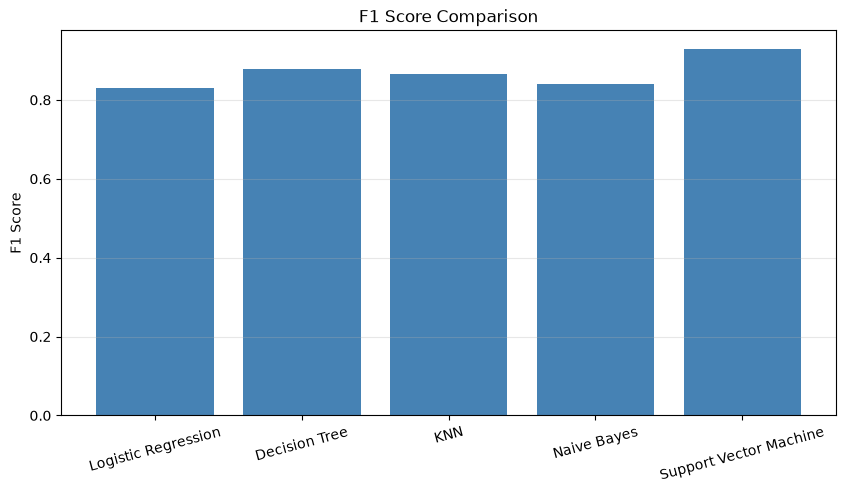

In [241]:
# ==========================================================
# F1 SCORE COMPARISON
# ==========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(

    results_df["Model"],

    results_df["F1"],

    color="steelblue"

)

plt.title(
    "F1 Score Comparison"
)

plt.ylabel(
    "F1 Score"
)

plt.xticks(rotation=15)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

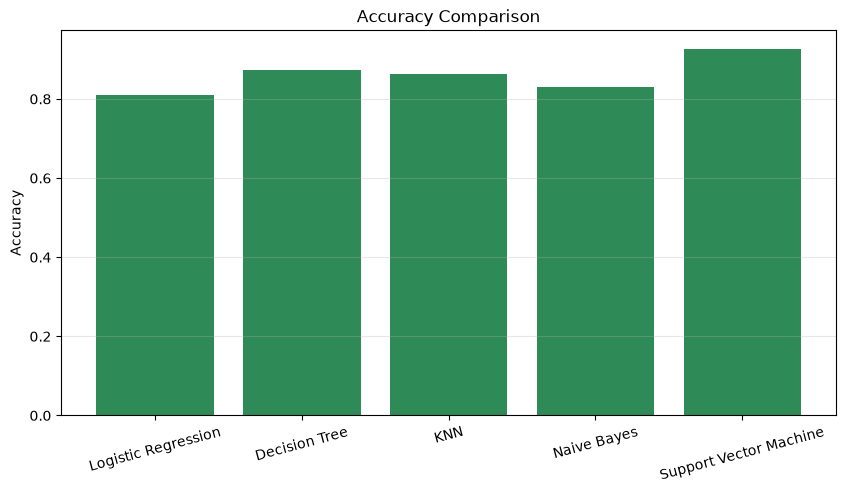

In [242]:
# ==========================================================
# ACCURACY COMPARISON
# ==========================================================

plt.figure(figsize=(10,5))

plt.bar(

    results_df["Model"],

    results_df["Accuracy"],

    color="seagreen"

)

plt.title(
    "Accuracy Comparison"
)

plt.ylabel(
    "Accuracy"
)

plt.xticks(rotation=15)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

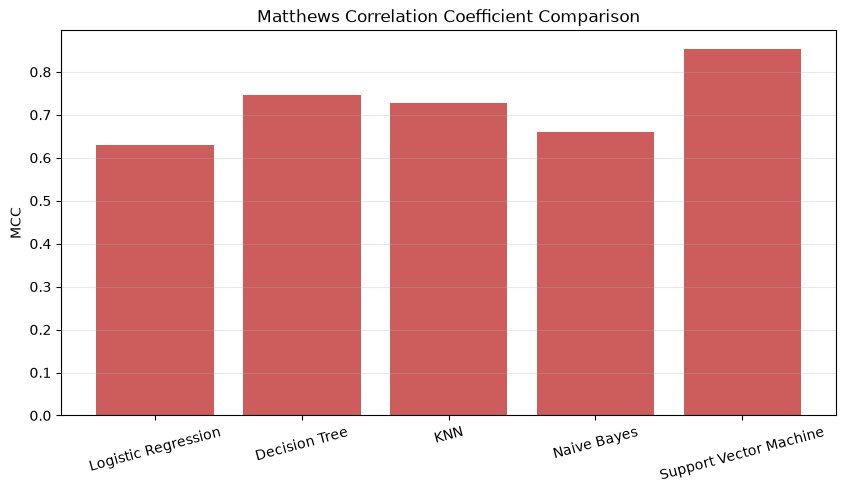

In [243]:
# ==========================================================
# MCC COMPARISON
# ==========================================================

plt.figure(figsize=(10,5))

plt.bar(

    results_df["Model"],

    results_df["MCC"],

    color="indianred"

)

plt.title(
    "Matthews Correlation Coefficient Comparison"
)

plt.ylabel(
    "MCC"
)

plt.xticks(rotation=15)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [244]:
# ==========================================================
# SAVE RESULTS TABLE
# ==========================================================

results_df.to_csv(

    "model_comparison_results.csv",

    index=False

)

print(
    "model_comparison_results.csv saved successfully"
)

model_comparison_results.csv saved successfully


In [245]:
# ==========================================================
# OBSERVATIONS TABLE
# ==========================================================

observations = pd.DataFrame({

    "ML Model Name":[

        "Logistic Regression",

        "Decision Tree",

        "KNN",

        "Naive Bayes",

        "Support Vector Machine"

    ],

    "Observation":[

        "Strong baseline model with good interpretability",

        "Easy to interpret but may overfit",

        "Distance-based classifier, sensitive to scaling",

        "Fast probabilistic model using Bayes theorem",

        "Margin-maximizing classifier with strong generalization"

    ]

})

print(observations)

            ML Model Name                                        Observation
0     Logistic Regression   Strong baseline model with good interpretability
1           Decision Tree                  Easy to interpret but may overfit
2                     KNN    Distance-based classifier, sensitive to scaling
3             Naive Bayes       Fast probabilistic model using Bayes theorem
4  Support Vector Machine  Margin-maximizing classifier with strong gener...


In [246]:
# ==========================================================
# SAVE OBSERVATIONS
# ==========================================================

observations.to_csv(

    "model_observations.csv",

    index=False

)

print(
    "model_observations.csv saved successfully"
)

model_observations.csv saved successfully


# Step 8 Observations

1. All five required classification models were trained and evaluated.

2. Performance was measured using:

   - Accuracy
   - AUC Score
   - Precision
   - Recall
   - F1 Score
   - MCC

3. Models were ranked using F1 Score.

4. The model with the highest F1 Score was selected as the best-performing model.

5. Comparison tables, ranking tables, and observation tables were generated for inclusion in:

   - README.md
   - Streamlit application
   - Final report

6. The best model identified in this section will be used in the Streamlit deployment.

# Step 9: Export Models and Project Artifacts

## Objective

Prepare all files required for:

1. GitHub repository submission
2. Streamlit deployment
3. Assignment evaluation

The following files will be generated:

- logistic_regression.pkl
- decision_tree.pkl
- knn.pkl
- naive_bayes.pkl
- svm.pkl
- scaler.pkl
- model_comparison_results.csv
- model_observations.csv
- test_data.csv

These files will later be used by the Streamlit application.

In [247]:
# ==========================================================
# CREATE PROJECT DIRECTORIES
# ==========================================================

import os

os.makedirs(
    "models",
    exist_ok=True
)

os.makedirs(
    "artifacts",
    exist_ok=True
)

print(
    "Directories Created Successfully"
)
# ==========================================================
# SAVE LOGISTIC REGRESSION
# ==========================================================

import joblib

joblib.dump(

    logistic_model,

    "models/logistic_regression.pkl"

)

print(
    "Logistic Regression Saved"
)
# ==========================================================
# SAVE DECISION TREE
# ==========================================================

joblib.dump(

    decision_tree_model,

    "models/decision_tree.pkl"

)

print(
    "Decision Tree Saved"
)
# ==========================================================
# SAVE KNN
# ==========================================================

joblib.dump(

    knn_model,

    "models/knn.pkl"

)

print(
    "KNN Saved"
)
# ==========================================================
# SAVE NAIVE BAYES
# ==========================================================

joblib.dump(

    naive_bayes_model,

    "models/naive_bayes.pkl"

)

print(
    "Naive Bayes Saved"
)
# ==========================================================
# SAVE SVM
# ==========================================================

joblib.dump(

    svm_model,

    "models/svm.pkl"

)

print(
    "SVM Saved"
)
# ==========================================================
# SAVE SCALER
# ==========================================================

joblib.dump(

    scaler,

    "models/scaler.pkl"

)

print(
    "Scaler Saved"
)
# ==========================================================
# SAVE MODEL COMPARISON RESULTS
# ==========================================================

results_df.to_csv(

    "artifacts/model_comparison_results.csv",

    index=False

)

print(
    "model_comparison_results.csv Saved"
)
# ==========================================================
# SAVE OBSERVATIONS TABLE
# ==========================================================

observations.to_csv(

    "artifacts/model_observations.csv",

    index=False

)

print(
    "model_observations.csv Saved"
)
# ==========================================================
# SAVE TEST DATASET
# ==========================================================

test_data = X_test.copy()

if not isinstance(
    test_data,
    pd.DataFrame
):

    test_data = pd.DataFrame(
        test_data,
        columns=X.columns
    )

test_data["target"] = y_test

test_data.to_csv(

    "test_data.csv",

    index=False

)

print(
    "test_data.csv Saved"
)

Directories Created Successfully
Logistic Regression Saved
Decision Tree Saved
KNN Saved
Naive Bayes Saved
SVM Saved
Scaler Saved
model_comparison_results.csv Saved
model_observations.csv Saved
test_data.csv Saved


In [248]:
# ==========================================================
# VERIFY SAVED FILES
# ==========================================================

print(
    "Models Folder\n"
)

print(
    os.listdir("models")
)

print(
    "\nArtifacts Folder\n"
)

print(
    os.listdir("artifacts")
)

Models Folder

['scaler.pkl', 'svm.pkl', 'decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'naive_bayes.pkl']

Artifacts Folder

['model_comparison_results.csv', 'model_observations.csv', 'readme_model_table.csv', 'readme_observations.csv']


In [249]:
# ==========================================================
# PROJECT INVENTORY
# ==========================================================

inventory = pd.DataFrame({

    "File":[

        "logistic_regression.pkl",

        "decision_tree.pkl",

        "knn.pkl",

        "naive_bayes.pkl",

        "svm.pkl",

        "scaler.pkl",

        "model_comparison_results.csv",

        "model_observations.csv",

        "test_data.csv"

    ],

    "Purpose":[

        "Logistic Regression Model",

        "Decision Tree Model",

        "KNN Model",

        "Naive Bayes Model",

        "Support Vector Machine Model",

        "Feature Scaling for Streamlit",

        "Metric Comparison Table",

        "Observation Table",

        "Assignment Test Dataset"

    ]

})

print(inventory)

                           File                        Purpose
0       logistic_regression.pkl      Logistic Regression Model
1             decision_tree.pkl            Decision Tree Model
2                       knn.pkl                      KNN Model
3               naive_bayes.pkl              Naive Bayes Model
4                       svm.pkl   Support Vector Machine Model
5                    scaler.pkl  Feature Scaling for Streamlit
6  model_comparison_results.csv        Metric Comparison Table
7        model_observations.csv              Observation Table
8                 test_data.csv        Assignment Test Dataset


# Step 9 Observations

1. All five trained machine learning models were successfully exported.

2. The scaler used during preprocessing was saved for future inference.

3. The model comparison table and observation table were stored as CSV files.

4. A test_data.csv file was generated as required by the assignment.

5. These exported files will be used by the Streamlit application and GitHub submission.

6. The project is now ready for:

   - README generation
   - requirements.txt creation
   - Streamlit application development
   - GitHub deployment

# Step 10: Generate README Content

## Objective

Prepare the content required for:

1. GitHub Repository
2. Project Documentation
3. Assignment Submission

The README will contain:

- Problem Statement
- Dataset Description
- Model Comparison Table
- Observation Table
- Final Conclusion

In [250]:
# ==========================================================
# README MODEL COMPARISON TABLE
# ==========================================================

readme_results = results_df.copy()

print("README MODEL COMPARISON TABLE\n")

print(readme_results)

print("\nMarkdown Format\n")

print(
    readme_results.to_markdown(
        index=False
    )
)

README MODEL COMPARISON TABLE

                    Model  Accuracy     AUC  Precision  Recall      F1     MCC
0     Logistic Regression    0.8098  0.9298     0.7619  0.9143  0.8312  0.6309
1           Decision Tree    0.8732  0.9326     0.8624  0.8952  0.8785  0.7465
2                     KNN    0.8634  0.9629     0.8738  0.8571  0.8654  0.7269
3             Naive Bayes    0.8293  0.9043     0.8070  0.8762  0.8402  0.6602
4  Support Vector Machine    0.9268  0.9771     0.9167  0.9429  0.9296  0.8538

Markdown Format

| Model                  |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.8098 | 0.9298 |      0.7619 |   0.9143 | 0.8312 | 0.6309 |
| Decision Tree          |     0.8732 | 0.9326 |      0.8624 |   0.8952 | 0.8785 | 0.7465 |
| KNN                    |     0.8634 | 0.9629 |      0.8738 |   0.8571 | 0.8654 | 0.7269 |
| Naive Bayes    

In [251]:
# ==========================================================
# DETERMINE BEST MODEL
# ==========================================================

best_model_row = (

    results_df

    .sort_values(
        by="F1",
        ascending=False
    )

    .iloc[0]

)

best_model_name = (
    best_model_row["Model"]
)

print("Best Model\n")

print(best_model_name)

print("\nBest Model Metrics\n")

print(best_model_row)

Best Model

Support Vector Machine

Best Model Metrics

Model        Support Vector Machine
Accuracy                     0.9268
AUC                          0.9771
Precision                    0.9167
Recall                       0.9429
F1                           0.9296
MCC                          0.8538
Name: 4, dtype: object


In [252]:
# ==========================================================
# README OBSERVATION TABLE
# ==========================================================

observation_table = pd.DataFrame({

    "ML Model Name":[

        "Logistic Regression",

        "Decision Tree",

        "KNN",

        "Naive Bayes",

        "Support Vector Machine",

        "Overall Winner"

    ],

    "Observation":[

        "Strong baseline model with high interpretability",

        "Interpretable decision rules but can overfit",

        "Distance-based model sensitive to scaling",

        "Fast probabilistic classifier with independence assumptions",

        "Margin-maximizing classifier with strong generalization",

        best_model_name

    ]

})

print(observation_table)

print("\nMarkdown Format\n")

print(
    observation_table.to_markdown(
        index=False
    )
)

            ML Model Name                                        Observation
0     Logistic Regression   Strong baseline model with high interpretability
1           Decision Tree       Interpretable decision rules but can overfit
2                     KNN          Distance-based model sensitive to scaling
3             Naive Bayes  Fast probabilistic classifier with independenc...
4  Support Vector Machine  Margin-maximizing classifier with strong gener...
5          Overall Winner                             Support Vector Machine

Markdown Format

| ML Model Name          | Observation                                                 |
|:-----------------------|:------------------------------------------------------------|
| Logistic Regression    | Strong baseline model with high interpretability            |
| Decision Tree          | Interpretable decision rules but can overfit                |
| KNN                    | Distance-based model sensitive to scaling                   

In [253]:
# ==========================================================
# SAVE README TABLES
# ==========================================================

readme_results.to_csv(

    "artifacts/readme_model_table.csv",

    index=False

)

observation_table.to_csv(

    "artifacts/readme_observations.csv",

    index=False

)

print(
    "README Tables Saved"
)

README Tables Saved


# Heart Disease Classification Using Machine Learning

## Student Details

Name: MAGESHWARAN P

BITS ID: 2026AK05470

---

# Problem Statement

The objective of this project is to predict whether a patient has heart disease using clinical and demographic information.

The dataset contains 13 features describing patient health characteristics, and the target variable indicates the presence or absence of heart disease.

---

# Dataset Description

Dataset: Heart Disease Prediction Dataset

Number of Records: 1025

Number of Input Features: 13

Target Variable:

target

0 = No Heart Disease

1 = Heart Disease

Features:

- age
- sex
- cp
- trestbps
- chol
- fbs
- restecg
- thalach
- exang
- oldpeak
- slope
- ca
- thal

---

# Models Implemented

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

---

# Model Comparison

Paste the generated comparison table here.

---

# Observations

Paste the generated observation table here.

---

# Best Model

The best-performing model was:

**PLACEHOLDER_BEST_MODEL**

based on the highest F1 Score.

---

# Files Included

- app.py
- requirements.txt
- test_data.csv
- Saved Models
- Source Notebook

---

# Streamlit Deployment

Paste Streamlit URL here after deployment.

---

# GitHub Repository

Paste GitHub Repository URL here.

In [254]:
# ==========================================================
# README SUMMARY
# ==========================================================

print("README SUMMARY\n")

print(
    f"The best-performing model was "
    f"{best_model_name}."
)

print(
    f"\nF1 Score = "
    f"{best_model_row['F1']:.4f}"
)

print(
    f"\nAccuracy = "
    f"{best_model_row['Accuracy']:.4f}"
)

README SUMMARY

The best-performing model was Support Vector Machine.

F1 Score = 0.9296

Accuracy = 0.9268


# Step 10 Observations

1. A model comparison table was generated in README-friendly format.

2. An observation table was generated as required by the assignment.

3. The best-performing model was identified using F1 Score.

4. A complete README template was prepared for GitHub submission.

5. Remaining tasks include:

   - requirements.txt
   - Streamlit application
   - GitHub upload
   - Streamlit deployment

# Step 11: Create requirements.txt

## Objective

Create the dependency file required for:

1. GitHub Repository
2. Streamlit Deployment
3. Reproducibility

The file lists all Python packages required to run:

- Machine Learning Models
- Data Processing
- Data Visualization
- Streamlit Application

In [255]:
# ==========================================================
# CREATE REQUIREMENTS.TXT
# ==========================================================

requirements_text = """
streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
"""

with open(
    "requirements.txt",
    "w"
) as file:

    file.write(
        requirements_text.strip()
    )

print(
    "requirements.txt created successfully"
)

requirements.txt created successfully


In [256]:
# ==========================================================
# DISPLAY REQUIREMENTS.TXT
# ==========================================================

with open(
    "requirements.txt",
    "r"
) as file:

    print(file.read())

streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn
joblib


In [257]:
# ==========================================================
# VERIFY FILE
# ==========================================================

import os

print(
    "requirements.txt exists:",
    os.path.exists(
        "requirements.txt"
    )
)

requirements.txt exists: True


# Step 11 Observations

1. The requirements.txt file was created successfully.

2. It contains all libraries required by the project.

3. This file is necessary for:

   - GitHub distribution
   - Streamlit Cloud deployment
   - Reproducibility

4. Streamlit uses this file during deployment to automatically install dependencies.

# Step 12: Streamlit Application

## Objective

Create a web application that allows users to:

1. Upload a CSV file.
2. Select a trained machine learning model.
3. Generate predictions.
4. View classification metrics.
5. View the confusion matrix.

The application will be deployed using Streamlit Cloud.

In [258]:
#pip install streamlit

In [259]:
# ==========================================================
# SAVE APP.PY
# ==========================================================

app_code = '''

# ==========================================================
# HEART DISEASE CLASSIFICATION DASHBOARD
# ==========================================================

import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import streamlit as st

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score
)


# ==========================================================
# PAGE CONFIGURATION
# ==========================================================

st.set_page_config(
    page_title="Heart Disease Classification Dashboard",
    page_icon="❤️",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ==========================================================
# CONSTANTS
# ==========================================================

FEATURE_COLUMNS = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

MODEL_FILES = {
    "Logistic Regression":
        "models/logistic_regression.pkl",

    "Decision Tree":
        "models/decision_tree.pkl",

    "KNN":
        "models/knn.pkl",

    "Naive Bayes":
        "models/naive_bayes.pkl",

    "Support Vector Machine":
        "models/svm.pkl"
}

METRIC_COLUMNS = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]


# ==========================================================
# LOAD SAVED MODELS
# ==========================================================

@st.cache_resource
def load_saved_artifacts():
    """
    Load the saved scaler and trained models.

    Streamlit caches the results so model files are not
    repeatedly loaded during widget interactions.
    """

    loaded_scaler = joblib.load(
        "models/scaler.pkl"
    )

    loaded_models = {}

    for model_name, model_path in MODEL_FILES.items():

        loaded_models[model_name] = (
            joblib.load(model_path)
        )

    return loaded_scaler, loaded_models


# ==========================================================
# CALCULATE REQUIRED METRICS
# ==========================================================

def calculate_metrics(
    y_true,
    predictions,
    probabilities
):
    """
    Calculate all metrics required by the assignment.

    AUC cannot be calculated when actual target values contain
    only one class. In that case, AUC is returned as NaN.
    """

    if pd.Series(y_true).nunique() == 2:

        auc_value = roc_auc_score(
            y_true,
            probabilities
        )

    else:

        auc_value = np.nan

    return {
        "Accuracy":
            accuracy_score(
                y_true,
                predictions
            ),

        "AUC":
            auc_value,

        "Precision":
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "MCC":
            matthews_corrcoef(
                y_true,
                predictions
            )
    }


# ==========================================================
# SIDEBAR
# ==========================================================

st.sidebar.title("Navigation")

st.sidebar.markdown("---")

st.sidebar.markdown(
    """
    ## ❤️ Heart Disease Classification

    ### Available Models

    - Logistic Regression
    - Decision Tree
    - K-Nearest Neighbors
    - Gaussian Naive Bayes
    - Support Vector Machine
    """
)

st.sidebar.markdown("---")

st.sidebar.success(
    """
    👨‍🎓 **Student Details**

    **Name:** MAGESHWARAN P

    **BITS ID:** 2026AK05470

    **Course:** Machine Learning

    **Assignment:** ML Assignment 2
    """
)

st.sidebar.markdown("---")


# ==========================================================
# SAMPLE DATASET DOWNLOAD
# ==========================================================

if os.path.exists("heart.csv"):

    with open("heart.csv", "rb") as sample_file:

        sample_dataset_bytes = sample_file.read()

    st.sidebar.download_button(
        label="📥 Download Sample heart.csv",
        data=sample_dataset_bytes,
        file_name="heart.csv",
        mime="text/csv",
        use_container_width=True
    )

else:

    st.sidebar.warning(
        "heart.csv was not found in the project folder."
    )


# ==========================================================
# MAIN HEADER
# ==========================================================

st.title(
    "❤️ Heart Disease Classification Dashboard"
)

st.markdown(
    """
    Upload a labelled Heart Disease CSV file to evaluate all
    five trained machine learning models on the same dataset.

    The application automatically:

    - Evaluates every trained model
    - Computes all required classification metrics
    - Ranks models by F1 Score
    - Identifies the winning model
    - Compares any selected model with the winner
    - Displays confusion matrices and predictions
    """
)


# ==========================================================
# LOAD MODEL ARTIFACTS
# ==========================================================

models_loaded = True
model_loading_error = None

try:

    scaler, models = load_saved_artifacts()

except Exception as error:

    models_loaded = False
    model_loading_error = str(error)


if not models_loaded:

    st.error(
        "The trained models or scaler could not be loaded."
    )

    st.code(
        model_loading_error
    )

    st.info(
        """
        Ensure the following files are available:

        models/scaler.pkl

        models/logistic_regression.pkl

        models/decision_tree.pkl

        models/knn.pkl

        models/naive_bayes.pkl

        models/svm.pkl
        """
    )


# ==========================================================
# DATASET UPLOAD
# ==========================================================

uploaded_file = st.file_uploader(
    "Upload a labelled Heart Disease CSV file",
    type=["csv"],
    help=(
        "The CSV must contain the 13 feature columns and "
        "a binary target column named target."
    )
)


# ==========================================================
# BEFORE DATASET UPLOAD
# ==========================================================

if uploaded_file is None:

    st.info(
        "Upload `test_data.csv`, or download and upload "
        "the sample `heart.csv` dataset."
    )

    st.subheader(
        "Required CSV Columns"
    )

    required_columns_df = pd.DataFrame(
        {
            "Column":
                FEATURE_COLUMNS + ["target"],

            "Purpose":
                (
                    ["Input feature"]
                    * len(FEATURE_COLUMNS)
                    + ["Actual class label"]
                )
        }
    )

    st.dataframe(
        required_columns_df,
        use_container_width=True,
        hide_index=True
    )


# ==========================================================
# PROCESS UPLOADED DATASET
# ==========================================================

elif models_loaded:

    # ------------------------------------------------------
    # READ CSV
    # ------------------------------------------------------

    try:

        data = pd.read_csv(
            uploaded_file
        )

    except Exception as error:

        st.error(
            f"The uploaded CSV could not be read: {error}"
        )

        st.stop()

    st.success(
        "Dataset uploaded successfully."
    )


    # ------------------------------------------------------
    # VALIDATE COLUMNS
    # ------------------------------------------------------

    required_columns = (
        FEATURE_COLUMNS + ["target"]
    )

    missing_columns = [
        column
        for column in required_columns
        if column not in data.columns
    ]

    extra_columns = [
        column
        for column in data.columns
        if column not in required_columns
    ]

    if missing_columns:

        st.error(
            "The uploaded dataset is missing required columns."
        )

        st.write(
            "Missing columns:",
            missing_columns
        )

        st.stop()

    if extra_columns:

        st.warning(
            "Extra columns were detected and will be ignored."
        )

        st.write(
            "Ignored columns:",
            extra_columns
        )


    # ------------------------------------------------------
    # PREPARE MODEL DATA
    # ------------------------------------------------------

    model_data = data[
        required_columns
    ].copy()

    if model_data.empty:

        st.error(
            "The uploaded dataset contains no records."
        )

        st.stop()


    # ------------------------------------------------------
    # CHECK MISSING VALUES
    # ------------------------------------------------------

    missing_value_count = int(
        model_data
        .isnull()
        .sum()
        .sum()
    )

    if missing_value_count > 0:

        st.error(
            "The uploaded dataset contains missing values."
        )

        missing_summary = (
            model_data
            .isnull()
            .sum()
        )

        missing_summary = (
            missing_summary[
                missing_summary > 0
            ]
        )

        st.dataframe(
            missing_summary.rename(
                "Missing Values"
            )
        )

        st.stop()


    # ------------------------------------------------------
    # CHECK TARGET VALUES
    # ------------------------------------------------------

    invalid_targets = (
        set(
            model_data["target"]
            .unique()
        )
        -
        {0, 1}
    )

    if invalid_targets:

        st.error(
            "The target column must contain only 0 and 1."
        )

        st.write(
            "Invalid target values:",
            sorted(invalid_targets)
        )

        st.stop()


    # ------------------------------------------------------
    # FEATURES AND TARGET
    # ------------------------------------------------------

    X = model_data[
        FEATURE_COLUMNS
    ].copy()

    y = (
        model_data["target"]
        .astype(int)
    )


    # ------------------------------------------------------
    # APPLY SAVED SCALER
    # ------------------------------------------------------

    try:

        X_scaled = scaler.transform(
            X
        )

    except Exception as error:

        st.error(
            f"Feature scaling failed: {error}"
        )

        st.info(
            "Ensure the uploaded feature columns match heart.csv."
        )

        st.stop()


    # ======================================================
    # EVALUATE ALL FIVE MODELS
    # ======================================================

    all_results = []
    model_outputs = {}

    for model_name, model in models.items():

        try:

            predictions = model.predict(
                X_scaled
            )

            # ----------------------------------------------
            # PROBABILITY SCORES
            # ----------------------------------------------

            if hasattr(
                model,
                "predict_proba"
            ):

                probabilities = (
                    model.predict_proba(
                        X_scaled
                    )[:, 1]
                )

            elif hasattr(
                model,
                "decision_function"
            ):

                raw_scores = (
                    model.decision_function(
                        X_scaled
                    )
                )

                score_min = (
                    raw_scores.min()
                )

                score_max = (
                    raw_scores.max()
                )

                if score_max > score_min:

                    probabilities = (
                        raw_scores
                        -
                        score_min
                    ) / (
                        score_max
                        -
                        score_min
                    )

                else:

                    probabilities = (
                        np.zeros_like(
                            raw_scores,
                            dtype=float
                        )
                    )

            else:

                probabilities = (
                    predictions.astype(float)
                )


            # ----------------------------------------------
            # MODEL METRICS
            # ----------------------------------------------

            metrics = calculate_metrics(
                y,
                predictions,
                probabilities
            )

            all_results.append(
                {
                    "Model":
                        model_name,

                    **metrics
                }
            )

            model_outputs[
                model_name
            ] = {
                "predictions":
                    predictions,

                "probabilities":
                    probabilities,

                "metrics":
                    metrics
            }

        except Exception as error:

            st.error(
                f"{model_name} evaluation failed: {error}"
            )


    if not all_results:

        st.error(
            "None of the trained models could be evaluated."
        )

        st.stop()


    # ======================================================
    # CREATE LEADERBOARD
    # ======================================================

    results_df = pd.DataFrame(
        all_results
    )

    results_df = (
        results_df
        .sort_values(
            by=[
                "F1",
                "MCC",
                "AUC"
            ],
            ascending=False,
            na_position="last"
        )
        .reset_index(
            drop=True
        )
    )

    results_df.insert(
        0,
        "Rank",
        range(
            1,
            len(results_df) + 1
        )
    )

    winner_row = (
        results_df.iloc[0]
    )

    winner_name = (
        winner_row["Model"]
    )

    winner_output = (
        model_outputs[
            winner_name
        ]
    )

    winner_metrics = (
        winner_output[
            "metrics"
        ]
    )


    # ======================================================
    # WINNER CONCLUSION AT TOP
    # ======================================================

    st.markdown("---")

    st.subheader(
        "🏆 Overall Model Conclusion"
    )

    winner_col1, winner_col2, winner_col3 = (
        st.columns(3)
    )

    winner_col1.metric(
        "Winning Model",
        winner_name
    )

    winner_col2.metric(
        "Winner F1 Score",
        f"{winner_row['F1']:.4f}"
    )

    winner_col3.metric(
        "Winner MCC",
        f"{winner_row['MCC']:.4f}"
    )

    st.success(
        (
            f"**{winner_name}** achieved the highest "
            f"F1 Score on the uploaded dataset."
        )
    )

    if pd.isna(
        winner_row["AUC"]
    ):

        st.warning(
            "AUC is unavailable because the uploaded target "
            "contains only one class."
        )


    # ======================================================
    # MODEL LEADERBOARD
    # ======================================================

    st.subheader(
        "📋 Model Leaderboard"
    )

    display_results_df = (
        results_df.copy()
    )

    display_results_df[
        METRIC_COLUMNS
    ] = (
        display_results_df[
            METRIC_COLUMNS
        ]
        .round(4)
    )

    st.dataframe(
        display_results_df,
        use_container_width=True,
        hide_index=True
    )

    leaderboard_csv = (
        display_results_df
        .to_csv(
            index=False
        )
    )

    st.download_button(
        label="📥 Download Model Comparison",
        data=leaderboard_csv,
        file_name="model_comparison.csv",
        mime="text/csv"
    )


    # ======================================================
    # SELECT MODEL FOR DETAILED COMPARISON
    # ======================================================

    st.markdown("---")

    model_names = list(
        models.keys()
    )

    selected_model_name = (
        st.selectbox(
            "Select a model for detailed comparison",
            model_names,
            index=model_names.index(
                winner_name
            )
        )
    )

    selected_output = (
        model_outputs[
            selected_model_name
        ]
    )

    selected_metrics = (
        selected_output[
            "metrics"
        ]
    )

    selected_is_winner = (
        selected_model_name
        ==
        winner_name
    )


    # ======================================================
    # WINNER SELECTED
    # ======================================================

    if selected_is_winner:

        st.subheader(
            f"🏆 {selected_model_name} is the Winning Model"
        )

        st.success(
            (
                f"**{selected_model_name}** is already the "
                "highest-ranked model. A winner-versus-winner "
                "comparison is not required."
            )
        )

        winner_summary_df = (
            pd.DataFrame(
                {
                    "Metric":
                        METRIC_COLUMNS,

                    "Score":
                        [
                            winner_metrics[
                                metric
                            ]
                            for metric
                            in METRIC_COLUMNS
                        ]
                }
            )
        )

        winner_summary_df[
            "Score"
        ] = (
            winner_summary_df[
                "Score"
            ]
            .round(4)
        )

        st.dataframe(
            winner_summary_df,
            use_container_width=True,
            hide_index=True
        )

        # --------------------------------------------------
        # WINNER PERFORMANCE CHART
        # --------------------------------------------------

        chart_values = [
            winner_metrics[
                metric
            ]
            for metric
            in METRIC_COLUMNS
        ]

        fig_winner, ax_winner = (
            plt.subplots(
                figsize=(10, 5)
            )
        )

        bars = ax_winner.bar(
            METRIC_COLUMNS,
            chart_values,
            color=[
                "#2563eb",
                "#0ea5e9",
                "#14b8a6",
                "#22c55e",
                "#84cc16",
                "#f59e0b"
            ]
        )

        ax_winner.set_title(
            f"{winner_name} Performance"
        )

        ax_winner.set_xlabel(
            "Metric"
        )

        ax_winner.set_ylabel(
            "Score"
        )

        ax_winner.set_ylim(
            -1.0,
            1.05
        )

        ax_winner.grid(
            axis="y",
            alpha=0.25
        )

        labels = []

        for value in chart_values:

            if pd.isna(value):
                labels.append("N/A")
            else:
                labels.append(
                    f"{value:.4f}"
                )

        ax_winner.bar_label(
            bars,
            labels=labels,
            padding=3
        )

        st.pyplot(
            fig_winner
        )

        plt.close(
            fig_winner
        )


    # ======================================================
    # NON-WINNER SELECTED
    # ======================================================

    else:

        st.subheader(
            (
                f"⚖️ {selected_model_name} "
                f"vs {winner_name}"
            )
        )

        st.info(
            (
                f"Comparing **{selected_model_name}** "
                f"against the winning model, "
                f"**{winner_name}**."
            )
        )

        # --------------------------------------------------
        # COMPARISON TABLE
        # --------------------------------------------------

        comparison_df = (
            pd.DataFrame(
                {
                    "Metric":
                        METRIC_COLUMNS,

                    "Selected Model":
                        [
                            selected_metrics[
                                metric
                            ]
                            for metric
                            in METRIC_COLUMNS
                        ],

                    "Winning Model":
                        [
                            winner_metrics[
                                metric
                            ]
                            for metric
                            in METRIC_COLUMNS
                        ]
                }
            )
        )

        comparison_display_df = (
            comparison_df.copy()
        )

        comparison_display_df[
            [
                "Selected Model",
                "Winning Model"
            ]
        ] = (
            comparison_display_df[
                [
                    "Selected Model",
                    "Winning Model"
                ]
            ]
            .round(4)
        )

        comparison_display_df = (
            comparison_display_df
            .rename(
                columns={
                    "Selected Model":
                        selected_model_name,

                    "Winning Model":
                        winner_name
                }
            )
        )

        st.dataframe(
            comparison_display_df,
            use_container_width=True,
            hide_index=True
        )

        # --------------------------------------------------
        # DIFFERENCE FROM WINNER
        # --------------------------------------------------

        difference_df = pd.DataFrame(
            {
                "Metric":
                    METRIC_COLUMNS,

                "Selected minus Winner":
                    [
                        (
                            selected_metrics[
                                metric
                            ]
                            -
                            winner_metrics[
                                metric
                            ]
                        )
                        for metric
                        in METRIC_COLUMNS
                    ]
            }
        )

        difference_df[
            "Selected minus Winner"
        ] = (
            difference_df[
                "Selected minus Winner"
            ]
            .round(4)
        )

        st.markdown(
            "#### Difference from Winning Model"
        )

        st.dataframe(
            difference_df,
            use_container_width=True,
            hide_index=True
        )

        # --------------------------------------------------
        # COMPARISON CHART
        # --------------------------------------------------

        comparison_plot_df = (
            comparison_df
            .set_index(
                "Metric"
            )
            [
                [
                    "Selected Model",
                    "Winning Model"
                ]
            ]
            .rename(
                columns={
                    "Selected Model":
                        selected_model_name,

                    "Winning Model":
                        winner_name
                }
            )
        )

        fig_compare, ax_compare = (
            plt.subplots(
                figsize=(11, 5)
            )
        )

        comparison_plot_df.plot(
            kind="bar",
            ax=ax_compare,
            color=[
                "#2563eb",
                "#16a34a"
            ]
        )

        ax_compare.set_title(
            "Selected Model Compared with Winning Model"
        )

        ax_compare.set_xlabel(
            "Metric"
        )

        ax_compare.set_ylabel(
            "Score"
        )

        ax_compare.set_ylim(
            -1.0,
            1.05
        )

        ax_compare.tick_params(
            axis="x",
            rotation=0
        )

        ax_compare.grid(
            axis="y",
            alpha=0.25
        )

        ax_compare.legend(
            title="Model"
        )

        st.pyplot(
            fig_compare
        )

        plt.close(
            fig_compare
        )


    # ======================================================
    # DETAILED TABS
    # ======================================================

    tab1, tab2, tab3, tab4 = st.tabs(
        [
            "📊 Selected Model Metrics",
            "📉 Confusion Matrix",
            "🔮 Predictions",
            "📂 Dataset"
        ]
    )


    # ======================================================
    # TAB 1: SELECTED MODEL METRICS
    # ======================================================

    with tab1:

        st.subheader(
            f"{selected_model_name} Performance"
        )

        metric_row1 = st.columns(3)

        metric_row1[0].metric(
            "Accuracy",
            f"{selected_metrics['Accuracy']:.4f}"
        )

        if pd.isna(
            selected_metrics["AUC"]
        ):

            selected_auc_text = "N/A"

        else:

            selected_auc_text = (
                f"{selected_metrics['AUC']:.4f}"
            )

        metric_row1[1].metric(
            "AUC",
            selected_auc_text
        )

        metric_row1[2].metric(
            "Precision",
            f"{selected_metrics['Precision']:.4f}"
        )

        metric_row2 = st.columns(3)

        metric_row2[0].metric(
            "Recall",
            f"{selected_metrics['Recall']:.4f}"
        )

        metric_row2[1].metric(
            "F1 Score",
            f"{selected_metrics['F1']:.4f}"
        )

        metric_row2[2].metric(
            "MCC",
            f"{selected_metrics['MCC']:.4f}"
        )

        if selected_is_winner:

            st.success(
                "The selected model is the overall winner."
            )

        else:

            f1_difference = (
                winner_metrics["F1"]
                -
                selected_metrics["F1"]
            )

            st.info(
                (
                    f"The selected model's F1 Score "
                    f"is {f1_difference:.4f} below "
                    f"{winner_name}."
                )
            )


    # ======================================================
    # TAB 2: CONFUSION MATRIX
    # ======================================================

    with tab2:

        selected_cm = confusion_matrix(
            y,
            selected_output[
                "predictions"
            ]
        )

        if selected_is_winner:

            st.subheader(
                (
                    f"{selected_model_name} "
                    "Confusion Matrix"
                )
            )

            fig_selected_cm, ax_selected_cm = (
                plt.subplots(
                    figsize=(6, 5)
                )
            )

            sns.heatmap(
                selected_cm,
                annot=True,
                fmt="d",
                cmap="Greens",
                cbar=False,
                xticklabels=[
                    "No Disease",
                    "Disease"
                ],
                yticklabels=[
                    "No Disease",
                    "Disease"
                ],
                ax=ax_selected_cm
            )

            ax_selected_cm.set_xlabel(
                "Predicted"
            )

            ax_selected_cm.set_ylabel(
                "Actual"
            )

            ax_selected_cm.set_title(
                f"Winner: {selected_model_name}"
            )

            st.pyplot(
                fig_selected_cm
            )

            plt.close(
                fig_selected_cm
            )

        else:

            winner_cm = confusion_matrix(
                y,
                winner_output[
                    "predictions"
                ]
            )

            cm_col1, cm_col2 = st.columns(2)

            with cm_col1:

                st.markdown(
                    f"### {selected_model_name}"
                )

                fig_selected_cm, ax_selected_cm = (
                    plt.subplots(
                        figsize=(5, 4)
                    )
                )

                sns.heatmap(
                    selected_cm,
                    annot=True,
                    fmt="d",
                    cmap="Blues",
                    cbar=False,
                    xticklabels=[
                        "No Disease",
                        "Disease"
                    ],
                    yticklabels=[
                        "No Disease",
                        "Disease"
                    ],
                    ax=ax_selected_cm
                )

                ax_selected_cm.set_xlabel(
                    "Predicted"
                )

                ax_selected_cm.set_ylabel(
                    "Actual"
                )

                st.pyplot(
                    fig_selected_cm
                )

                plt.close(
                    fig_selected_cm
                )

            with cm_col2:

                st.markdown(
                    f"### Winner: {winner_name}"
                )

                fig_winner_cm, ax_winner_cm = (
                    plt.subplots(
                        figsize=(5, 4)
                    )
                )

                sns.heatmap(
                    winner_cm,
                    annot=True,
                    fmt="d",
                    cmap="Greens",
                    cbar=False,
                    xticklabels=[
                        "No Disease",
                        "Disease"
                    ],
                    yticklabels=[
                        "No Disease",
                        "Disease"
                    ],
                    ax=ax_winner_cm
                )

                ax_winner_cm.set_xlabel(
                    "Predicted"
                )

                ax_winner_cm.set_ylabel(
                    "Actual"
                )

                st.pyplot(
                    fig_winner_cm
                )

                plt.close(
                    fig_winner_cm
                )


    # ======================================================
    # TAB 3: PREDICTIONS
    # ======================================================

    with tab3:

        prediction_df = (
            model_data.copy()
        )

        if selected_is_winner:

            prediction_df[
                f"{winner_name} Prediction"
            ] = (
                winner_output[
                    "predictions"
                ]
            )

            prediction_df[
                f"{winner_name} Probability"
            ] = (
                winner_output[
                    "probabilities"
                ]
            )

        else:

            prediction_df[
                f"{selected_model_name} Prediction"
            ] = (
                selected_output[
                    "predictions"
                ]
            )

            prediction_df[
                f"{selected_model_name} Probability"
            ] = (
                selected_output[
                    "probabilities"
                ]
            )

            prediction_df[
                f"{winner_name} Prediction"
            ] = (
                winner_output[
                    "predictions"
                ]
            )

            prediction_df[
                f"{winner_name} Probability"
            ] = (
                winner_output[
                    "probabilities"
                ]
            )

        st.dataframe(
            prediction_df.head(25),
            use_container_width=True
        )

        if selected_is_winner:

            distribution_df = pd.DataFrame(
                {
                    winner_name:
                        pd.Series(
                            winner_output[
                                "predictions"
                            ]
                        )
                        .value_counts()
                }
            )

        else:

            distribution_df = pd.DataFrame(
                {
                    selected_model_name:
                        pd.Series(
                            selected_output[
                                "predictions"
                            ]
                        )
                        .value_counts(),

                    winner_name:
                        pd.Series(
                            winner_output[
                                "predictions"
                            ]
                        )
                        .value_counts()
                }
            )

        distribution_df = (
            distribution_df
            .fillna(0)
            .reindex(
                [0, 1],
                fill_value=0
            )
        )

        distribution_df.index = [
            "No Disease",
            "Disease"
        ]

        fig_distribution, ax_distribution = (
            plt.subplots(
                figsize=(8, 4)
            )
        )

        if selected_is_winner:

            distribution_colors = [
                "#16a34a"
            ]

        else:

            distribution_colors = [
                "#2563eb",
                "#16a34a"
            ]

        distribution_df.plot(
            kind="bar",
            ax=ax_distribution,
            color=distribution_colors
        )

        ax_distribution.set_title(
            "Prediction Distribution"
        )

        ax_distribution.set_xlabel(
            "Predicted Class"
        )

        ax_distribution.set_ylabel(
            "Number of Records"
        )

        ax_distribution.tick_params(
            axis="x",
            rotation=0
        )

        st.pyplot(
            fig_distribution
        )

        plt.close(
            fig_distribution
        )

        predictions_csv = (
            prediction_df
            .to_csv(
                index=False
            )
        )

        st.download_button(
            label="📥 Download Detailed Predictions",
            data=predictions_csv,
            file_name=(
                "heart_disease_predictions.csv"
            ),
            mime="text/csv"
        )


    # ======================================================
    # TAB 4: DATASET
    # ======================================================

    with tab4:

        st.subheader(
            "Dataset Summary"
        )

        (
            dataset_col1,
            dataset_col2,
            dataset_col3,
            dataset_col4
        ) = st.columns(4)

        dataset_col1.metric(
            "Rows",
            model_data.shape[0]
        )

        dataset_col2.metric(
            "Input Features",
            len(FEATURE_COLUMNS)
        )

        dataset_col3.metric(
            "Missing Values",
            int(
                model_data
                .isnull()
                .sum()
                .sum()
            )
        )

        dataset_col4.metric(
            "Target Classes",
            int(
                y.nunique()
            )
        )

        st.subheader(
            "Dataset Preview"
        )

        st.dataframe(
            model_data.head(20),
            use_container_width=True
        )

        st.subheader(
            "Feature Statistics"
        )

        st.dataframe(
            model_data
            .describe()
            .T,
            use_container_width=True
        )

        st.subheader(
            "Target Distribution"
        )

        target_distribution = (
            y.value_counts()
            .sort_index()
            .rename(
                index={
                    0: "No Disease",
                    1: "Disease"
                }
            )
        )

        st.bar_chart(
            target_distribution
        )


# ==========================================================
# FOOTER
# ==========================================================

st.markdown("---")

st.caption(
    "Machine Learning Assignment 2 | "
    "MAGESHWARAN P | "
    "BITS ID: 2026AK05470"
)
'''

with open(
    "app.py",
    "w"
) as f:

    f.write(app_code)

print(
    "app.py created successfully"
)

app.py created successfully
